## 1. Loading the Taxis Dataset

In [2]:
import seaborn as sns
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

In [36]:
df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


## 2. Handling Missing Values

In [22]:
# 1 Check for missing values

df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [47]:
# 2 Impute missing values
df['pickup_zone']=df['pickup_zone'].fillna(df['pickup_zone'].mode()[0])
df['payment']=df['payment'].fillna(df['payment'].mode()[0])
df['pickup_borough']=df['pickup_borough'].fillna(df['pickup_borough'].mode()[0])
df['dropoff_zone']=df['dropoff_zone'].fillna(df['dropoff_zone'].mode()[0])
df['dropoff_borough']=df['dropoff_borough'].fillna(df['dropoff_borough'].mode()[0])

In [48]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

In [ ]:
# 3. remove rows with missing values
df = df.dropna(subset=['pickup','dropoff'])

### 1 line chart

In [55]:
import pandas as pd
import matplotlib.pyplot as plt

In [61]:
df['pickup']= pd.to_datetime(df['pickup'])
df = df.sort_values('pickup')

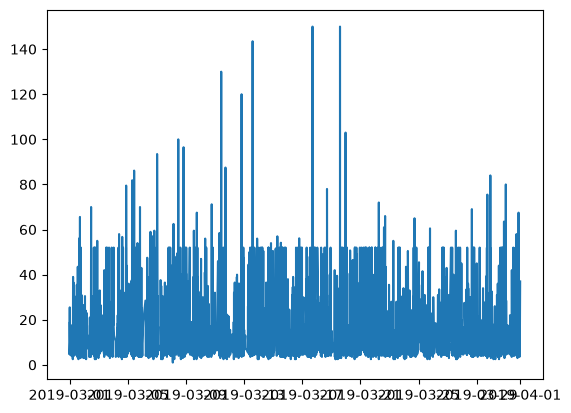

In [62]:
plt.plot(df['pickup'],df['fare'])
plt.show()

### 2. Bar Chart

In [63]:
fare_by_borough = df.groupby('pickup_borough')['fare'].sum()
print(fare_by_borough)

pickup_borough
Bronx         2078.91
Brooklyn      6327.48
Manhattan    59426.42
Queens       16382.06
Name: fare, dtype: float64


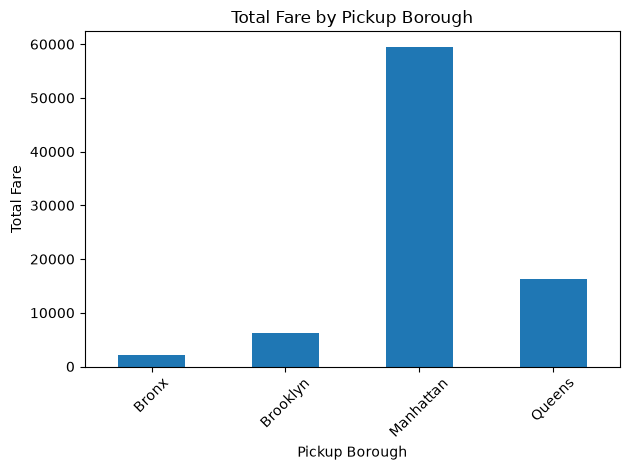

In [64]:
import matplotlib.pyplot as plt

fare_by_borough.plot(kind='bar')

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 3.Pie Chart

In [66]:
payment_counts = df['payment'].value_counts()
print(payment_counts)

payment
credit card    4621
cash           1812
Name: count, dtype: int64


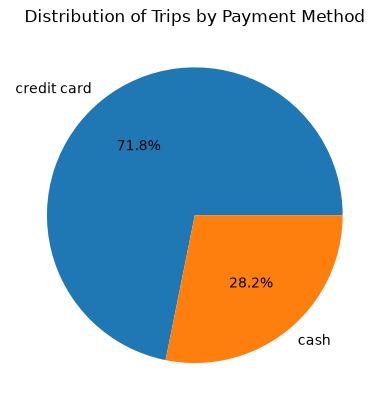

In [67]:
import matplotlib.pyplot as plt

payment_counts.plot(kind='pie', autopct='%1.1f%%')

plt.title('Distribution of Trips by Payment Method')
plt.ylabel('')
plt.show()

### 4.Histogram

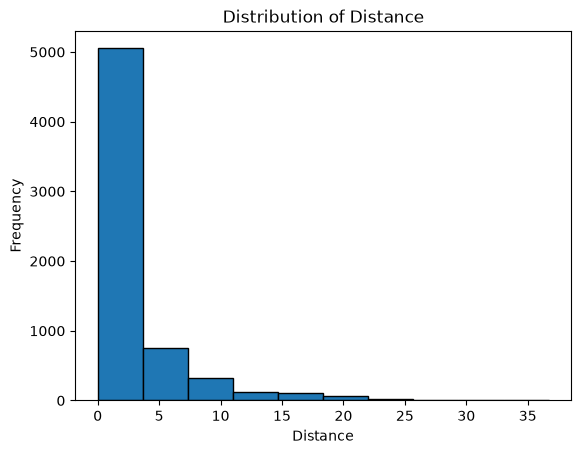

In [68]:
import matplotlib.pyplot as plt

plt.hist(df['distance'], bins=10, edgecolor='black')

plt.title('Distribution of Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')
plt.show()

### 5.Box Plot

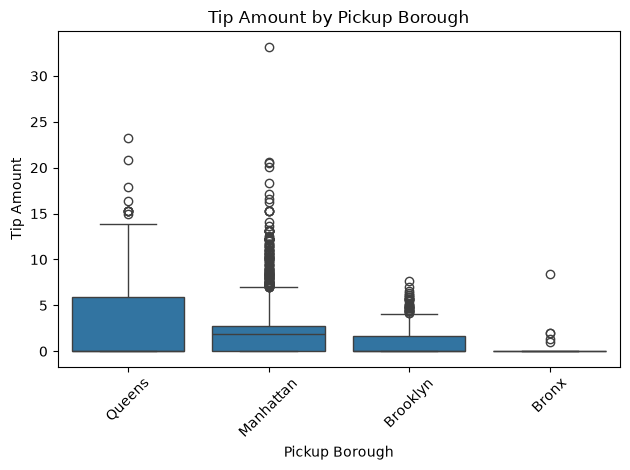

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(data=df, x='pickup_borough', y='tip')

plt.title('Tip Amount by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Visualizations using Seaborn:

### 1.Count Plot

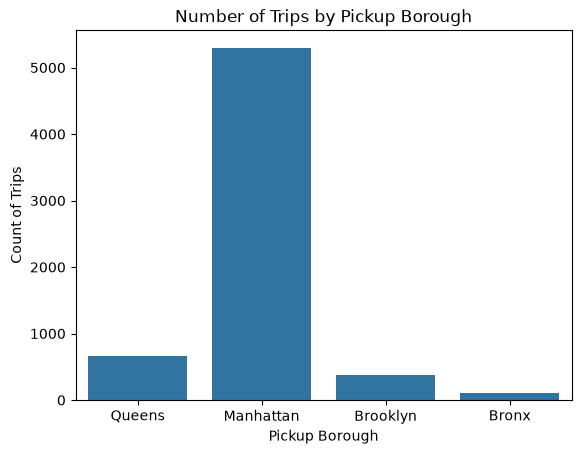

In [71]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x='pickup_borough')

plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Count of Trips')
plt.show()

### 2.Scatter Plot

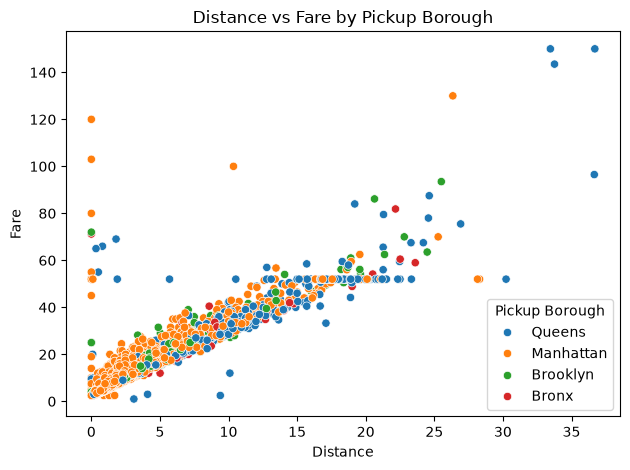

In [72]:
sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough'
)

plt.title('Distance vs Fare by Pickup Borough')
plt.xlabel('Distance')
plt.ylabel('Fare')
plt.legend(title='Pickup Borough')
plt.tight_layout()
plt.show()

### 3.Heatmap

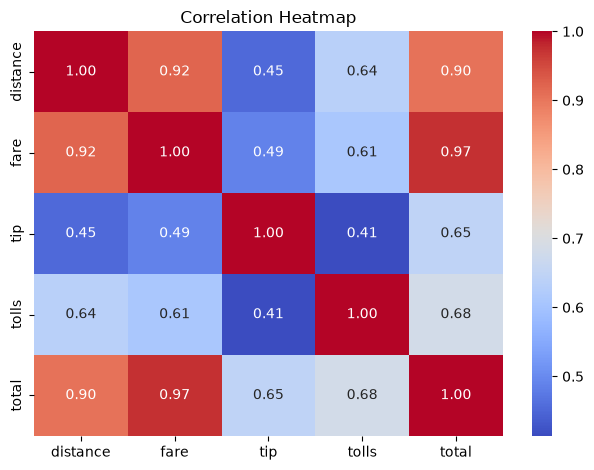

In [73]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns
numerical_data = df[['distance', 'fare', 'tip', 'tolls', 'total']]

# Create correlation matrix
correlation_matrix = numerical_data.corr()

# Plot heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

### 4.Pair Plot

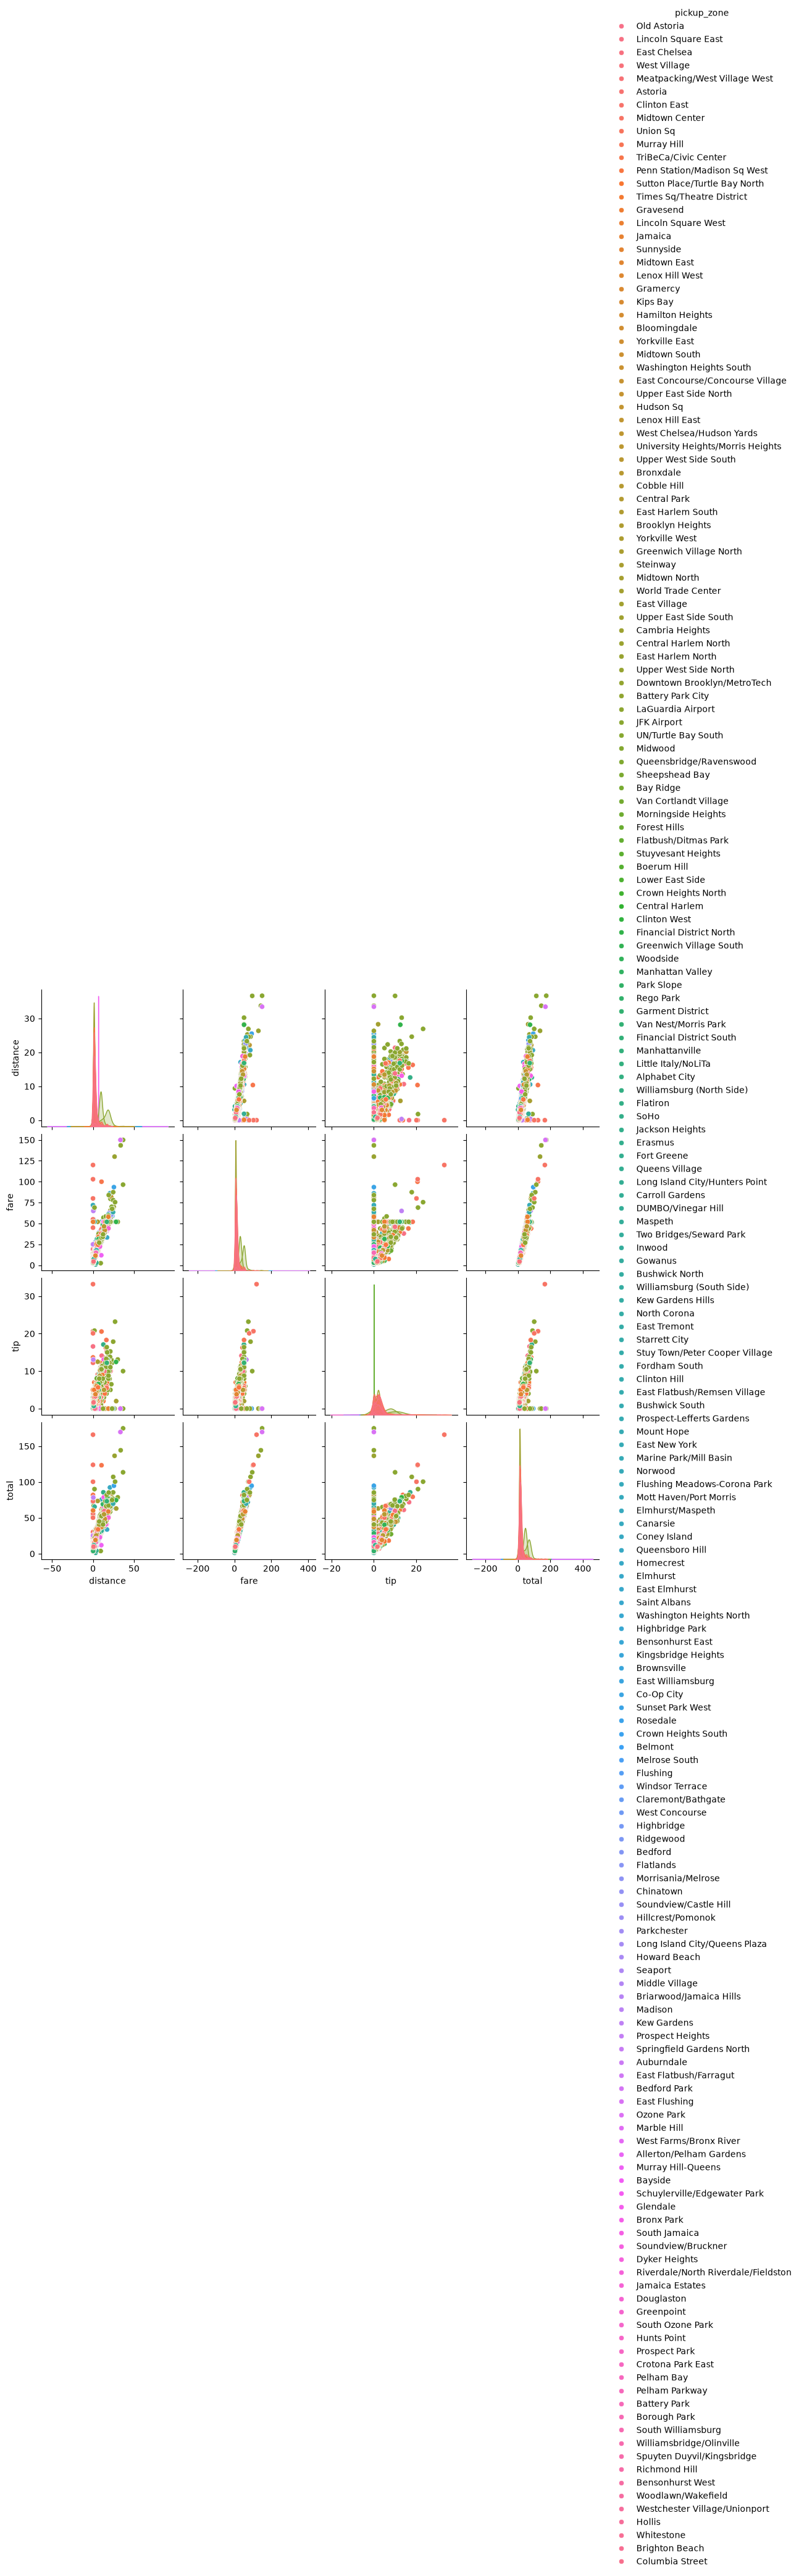

In [75]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(
    df,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone'
)

plt.show()

### 5.Violin Plot

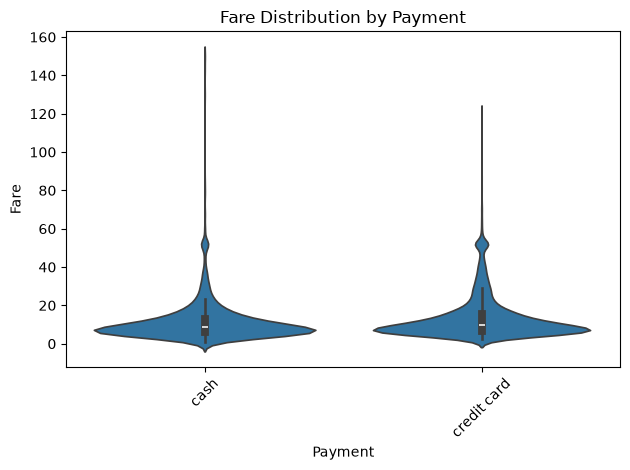

In [79]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.violinplot(data=df, x='payment', y='fare')

plt.title('Fare Distribution by Payment')
plt.xlabel('Payment')
plt.ylabel('Fare')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
